# 03 · Classical baseline: logistic regression

**Why a baseline?** The director asks whether a neural network is worth it, or whether *a simpler classical model would do the job*. To answer, we first need the score of that simple model: it is **the number every neural network must beat** 

Logistic regression is **one neuron** : $z = w^\top x + b$, $a = \sigma(z)$. With $C$ classes we use one neuron per class and a softmax. It is exactly an MLP **without hidden layer**: it can only draw straight boundaries (hyperplanes) in pixel space .

| Part | What we do |
|---|---|
| 1 | Data: the team's shared pipeline (same split as every other model) |
| 2 | The floor: chance level |
| 3 | Logistic regression with scikit-learn, regularisation chosen on validation |
| 4 | The same model as one PyTorch layer `nn.Linear`, trained with the 5-line loop |
| 5 | Final test score (once), confusion matrix, CPU cost for the kiosk |

## 0. Setup

In [9]:
import json, math, time, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits          # installed with scikit-learn

sys.path.insert(0, "../src")                          # so that "import museum_guide" finds the team's code
from museum_guide.data import prepare_subset, make_loaders

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

ROOT = Path("..")
LABEL = "genre"          # "genre" or "style"
DOWNSAMPLE = True        # 128 -> 64 px, exactly like the MLP notebook, so that both models see the same inputs
C_GRID = [0.0001, 0.0003, 0.001, 0.01, 0.1]         # inverse regularisation strength of scikit-learn, chosen on validation
EPOCHS_TORCH = 30

FIG_DIR = ROOT / "results" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = ROOT / "results"
print("device:", device)

device: cpu


## 1. Data
`prepare_subset` (shared code, `src/museum_guide/data.py`) loads the images, splits them 70 / 15 / 15 with the same class proportions (seed 0) and standardises them with the **training** statistics only.
Like the MLP, we halve the resolution to 64×64 and **flatten** each image into a vector of $3 \times 64 \times 64 = 12\,288$ numbers: logistic regression takes a vector, one weight per pixel value.

In [2]:
data = prepare_subset(LABEL, seed=SEED)
class_names = data["classes"]; C = len(class_names)
X_all, y_all = data["X"], data["y"]
idx = {"train": data["train_idx"], "val": data["val_idx"], "test": data["test_idx"]}
if DOWNSAMPLE:
    X_all = torch.nn.functional.avg_pool2d(X_all, kernel_size=2)       # (N, 3, 128, 128) -> (N, 3, 64, 64)
IMG_SIZE = X_all.shape[-1]

# Flattened NumPy arrays for scikit-learn: one row per image
Xf = {s: X_all[torch.as_tensor(i)].flatten(1).numpy() for s, i in idx.items()}
yf = {s: y_all[torch.as_tensor(i)].numpy() for s, i in idx.items()}
N_IN = Xf["train"].shape[1]

print(C, "classes:", class_names)
for s in Xf: print(f"{s:5s} X {Xf[s].shape}  y {yf[s].shape}")

11 classes: ['Unknown Genre', 'abstract_painting', 'cityscape', 'genre_painting', 'illustration', 'landscape', 'nude_painting', 'portrait', 'religious_painting', 'sketch_and_study', 'still_life']
train X (2309, 12288)  y (2309,)
val   X (496, 12288)  y (496,)
test  X (495, 12288)  y (495,)


## 2. The floor: chance level
With $C$ balanced classes, answering at random gives an accuracy of $1/C$. Any model must be clearly above it.

In [6]:
chance = 1 / C
majority = np.bincount(yf["train"]).argmax()
majority_acc = accuracy_score(yf["val"], np.full_like(yf["val"], majority))
print(f"chance level 1/C = {chance:.3f} | 'always the most frequent class' on validation = {majority_acc:.3f}")

chance level 1/C = 0.091 | 'always the most frequent class' on validation = 0.091


## 3. Logistic regression with scikit-learn
`LogisticRegression` minimises the cross-entropy (the log loss of S02, generalised to $C$ classes in S04) plus an L2 penalty on the weights.
`C` is the **inverse** of the regularisation strength: small `C` = strong regularisation. With 12 288 weights per class and only ~2 300 training images, the model can easily over-fit, so we **choose `C` on the validation set** (never on the test set, S04).

C = 0.0001 train acc 0.446 | val acc 0.268 | fit 10 s
C = 0.0003 train acc 0.573 | val acc 0.256 | fit 13 s
C = 0.001  train acc 0.772 | val acc 0.256 | fit 19 s
C = 0.01   train acc 0.983 | val acc 0.216 | fit 29 s
C = 0.1    train acc 0.998 | val acc 0.204 | fit 39 s

chosen on validation: C = 0.0001  (val acc 0.268)


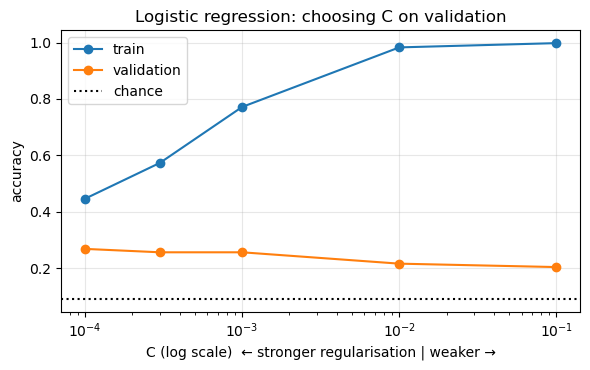

In [7]:
runs = {}
for c_reg in C_GRID:
    clf = LogisticRegression(C=c_reg, max_iter=1000)
    t0 = time.time()
    clf.fit(Xf["train"], yf["train"])
    fit_s = time.time() - t0
    runs[c_reg] = {"model": clf, "fit_s": fit_s,
                   "train_acc": clf.score(Xf["train"], yf["train"]),
                   "val_acc": clf.score(Xf["val"], yf["val"])}
    print(f"C = {c_reg:<6g} train acc {runs[c_reg]['train_acc']:.3f} | val acc {runs[c_reg]['val_acc']:.3f} | fit {fit_s:.0f} s")

best_C = max(runs, key=lambda c: runs[c]["val_acc"])
logreg = runs[best_C]["model"]
print(f"\nchosen on validation: C = {best_C}  (val acc {runs[best_C]['val_acc']:.3f})")

plt.figure(figsize=(6, 3.8))
plt.plot(C_GRID, [runs[c]["train_acc"] for c in C_GRID], "o-", label="train")
plt.plot(C_GRID, [runs[c]["val_acc"] for c in C_GRID], "o-", label="validation")
plt.axhline(chance, ls=":", c="k", label="chance")
plt.xscale("log"); plt.xlabel("C (log scale)  ← stronger regularisation | weaker →"); plt.ylabel("accuracy")
plt.title("Logistic regression: choosing C on validation"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_choose_C.png", dpi=150); plt.show()

**Reading:** the gap between train and validation accuracy shows over-fitting when `C` is large (weak regularisation): with `C = 0.1` the model reaches 99.8 % on train but only 20.4 % on validation (gap of 79 points). Stronger regularisation reduces the gap to 18 points (44.6 % vs 26.8 % at `C = 0.0001`). The validation accuracy is best for **`C = 0.0001` (26.8 %)**. Between `C = 0.0001` and `C = 0.001` the validation scores differ by about 1 point (≈ 6 images out of 496), which is within the noise; going even smaller would make the model under-fit (train accuracy already down to 44.6 %).

## 4. The same model in PyTorch: one `nn.Linear` layer
To show that the baseline is really "one neuron per class", we build it with PyTorch primitives and train it with **the five lines** of the course (S04): forward, loss, `zero_grad`, `backward`, `step`.
`nn.CrossEntropyLoss` receives the raw logits and applies the softmax itself. `weight_decay` plays the role of scikit-learn's L2 penalty.

135,179 parameters = 11 x (12288 + 1)
epoch  1 | train loss 2.295 acc 0.185 | val loss 2.274 acc 0.173
epoch  2 | train loss 2.243 acc 0.201 | val loss 2.245 acc 0.192
epoch  3 | train loss 2.212 acc 0.222 | val loss 2.225 acc 0.206
epoch  4 | train loss 2.188 acc 0.233 | val loss 2.216 acc 0.204
epoch  5 | train loss 2.168 acc 0.238 | val loss 2.214 acc 0.208
epoch  6 | train loss 2.151 acc 0.240 | val loss 2.201 acc 0.200
epoch  7 | train loss 2.134 acc 0.256 | val loss 2.193 acc 0.220
epoch  8 | train loss 2.125 acc 0.268 | val loss 2.181 acc 0.210
epoch  9 | train loss 2.111 acc 0.270 | val loss 2.179 acc 0.214
epoch 10 | train loss 2.098 acc 0.282 | val loss 2.182 acc 0.214
epoch 11 | train loss 2.088 acc 0.283 | val loss 2.180 acc 0.214
epoch 12 | train loss 2.078 acc 0.287 | val loss 2.173 acc 0.220
epoch 13 | train loss 2.069 acc 0.294 | val loss 2.172 acc 0.228
epoch 14 | train loss 2.061 acc 0.296 | val loss 2.168 acc 0.238
epoch 15 | train loss 2.051 acc 0.297 | val loss 2.1

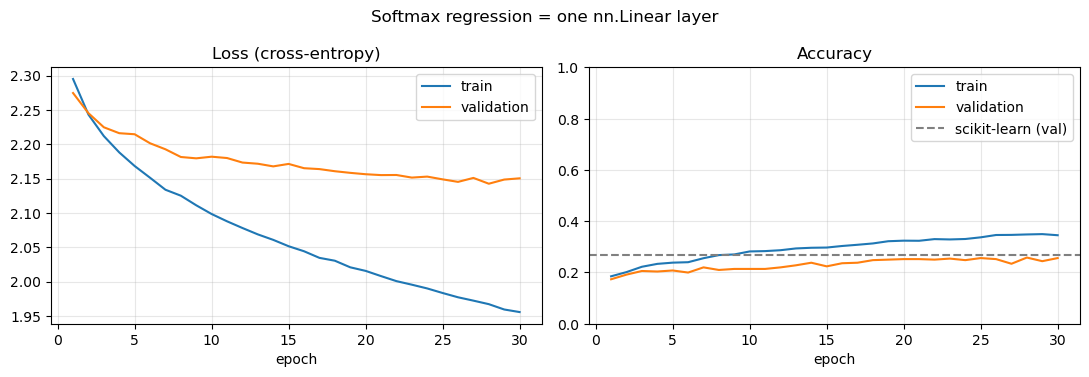

best validation accuracy: PyTorch 0.258 vs scikit-learn 0.268


In [10]:
train_loader, val_loader, test_loader = make_loaders(X_all, y_all, idx["train"], idx["val"], idx["test"])

torch.manual_seed(SEED)
softmax_reg = nn.Sequential(nn.Flatten(), nn.Linear(N_IN, C)).to(device)   # z = W x + b, one row of W per class
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(softmax_reg.parameters(), lr=0.0001, weight_decay=1e-2)  # smaller step, stronger L2
print(f"{sum(p.numel() for p in softmax_reg.parameters()):,} parameters = {C} x ({N_IN} + 1)")

def evaluate(model, loader):
    model.eval(); total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item(); n += len(yb)
    return total_loss / n, correct / n

hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
for epoch in range(1, EPOCHS_TORCH + 1):
    softmax_reg.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = softmax_reg(xb)          # 1. forward
        loss = loss_fn(logits, yb)        # 2. loss
        optimizer.zero_grad()             # 3. reset the gradients
        loss.backward()                   # 4. backpropagation
        optimizer.step()                  # 5. update
    tl, ta = evaluate(softmax_reg, train_loader); vl, va = evaluate(softmax_reg, val_loader)
    for k, v in zip(hist, [tl, vl, ta, va]): hist[k].append(v)
    print(f"epoch {epoch:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); ep = range(1, EPOCHS_TORCH + 1)
ax[0].plot(ep, hist["train_loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="validation")
ax[1].plot(ep, hist["train_acc"], label="train"); ax[1].plot(ep, hist["val_acc"], label="validation")
ax[1].axhline(runs[best_C]["val_acc"], ls="--", c="grey", label="scikit-learn (val)")
ax[0].set(title="Loss (cross-entropy)", xlabel="epoch"); ax[1].set(title="Accuracy", xlabel="epoch", ylim=(0, 1))
for a in ax: a.legend(); a.grid(alpha=.3)
fig.suptitle("Softmax regression = one nn.Linear layer"); fig.tight_layout()
fig.savefig(FIG_DIR / "baseline_pytorch_curves.png", dpi=150); plt.show()
print(f"best validation accuracy: PyTorch {max(hist['val_acc']):.3f} vs scikit-learn {runs[best_C]['val_acc']:.3f}")

**Reading:** the two implementations reach a similar validation accuracy (**25.8 % for PyTorch vs 26.8 % for scikit-learn**, a difference of 1 point ≈ 5 images out of 496, within the noise): same model, same loss, two optimisers. The initial loss (≈ 2.30) is close to $\ln 11 = 2.40$, as expected for an untrained network (S08). With a first learning rate of 0.001 the curves oscillated (the step was too large for 12 288 inputs, S02); with lr = 0.0001 and a stronger weight decay (1e-2) they are smooth: the training loss keeps decreasing (1.96 at epoch 30) while the validation loss levels off around 2.15, the start of a mild over-fitting. The difference with the MLP of the other notebook is only the **hidden layers** (S03).

## 5. Final evaluation on the test set (once) and cost for the kiosk
The reported baseline is the scikit-learn model with the `C` chosen on validation. The test set is used only now.
The kiosk has a modest CPU: we time **one prediction for one image with one CPU thread**.

TEST accuracy = 0.289   (chance 0.091)


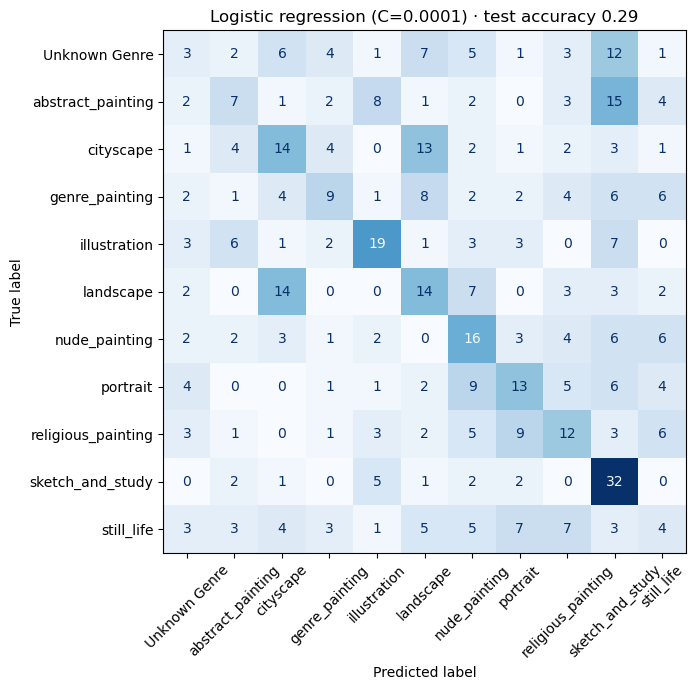

  sketch_and_study       0.71
  illustration           0.42
  nude_painting          0.36
  cityscape              0.31
  landscape              0.31
  portrait               0.29
  religious_painting     0.27
  genre_painting         0.20
  abstract_painting      0.16
  still_life             0.09
  Unknown Genre          0.07
most frequent mistake: true 'abstract_painting' predicted as 'sketch_and_study' (15 times)


In [11]:
y_pred = logreg.predict(Xf["test"])
test_acc = accuracy_score(yf["test"], y_pred)
print(f"TEST accuracy = {test_acc:.3f}   (chance {chance:.3f})")

cm = confusion_matrix(yf["test"], y_pred, labels=range(C))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues")
ax.set_title(f"Logistic regression (C={best_C}) · test accuracy {test_acc:.2f}"); fig.tight_layout()
fig.savefig(FIG_DIR / "baseline_confusion_test.png", dpi=150); plt.show()

per_class = cm.diagonal() / cm.sum(axis=1)
for name, acc in sorted(zip(class_names, per_class), key=lambda t: -t[1]):
    print(f"  {name:22s} {acc:.2f}")
off = cm.copy(); np.fill_diagonal(off, 0); i, j = np.unravel_index(off.argmax(), off.shape)
if off[i, j] > 0:
    print(f"most frequent mistake: true '{class_names[i]}' predicted as '{class_names[j]}' ({off[i, j]} times)")

In [12]:
x_one = Xf["test"][:1]
with threadpool_limits(limits=1):                     # one CPU thread, like a modest kiosk
    for _ in range(10): logreg.predict(x_one)
    times = []
    for _ in range(200):
        t0 = time.perf_counter(); logreg.predict(x_one); times.append((time.perf_counter() - t0) * 1000)
ms = float(np.median(times))

n_parameters = logreg.coef_.size + logreg.intercept_.size
result = {"model": "baseline_logreg", "test_accuracy": round(float(test_acc), 4), "cpu_ms_per_image": round(ms, 3),
          "n_parameters": int(n_parameters), "size_mb": round(n_parameters * 8 / 1e6, 1),
          "train_time_s": round(runs[best_C]["fit_s"], 1), "n_classes": C, "img_size": IMG_SIZE, "C": best_C}
print(json.dumps(result, indent=2))
(RES_DIR / "baseline_logreg.json").write_text(json.dumps(result, indent=2))

{
  "model": "baseline_logreg",
  "test_accuracy": 0.2889,
  "cpu_ms_per_image": 0.041,
  "n_parameters": 135179,
  "size_mb": 1.1,
  "train_time_s": 10.0,
  "n_classes": 11,
  "img_size": 64,
  "C": 0.0001
}


208

## Conclusions
1. **Score**: logistic regression on raw pixels reaches **28.9 %** on the test set (26.8 % on validation), **3.2× the chance level** (1/11 = 9.1 %).
2. **Regularisation**: without enough L2 penalty the model memorises the training set (99.8 % train vs 20.4 % validation). A strong penalty (C = 0.0001, chosen on validation) cuts the train/validation gap from 79 to 18 points.
3. **What it recognises**: the model only sees colours and their position. It recognises *sketch_and_study* well (71 %, nearly monochrome), but confuses *cityscape* and *landscape* (same sky/ground layout), *portrait*, *nude* and *religious* (skin tones in the centre), and mistakes *abstract* for *sketch* (15 times). *still_life* (9 %) and the catch-all *Unknown Genre* (7 %) stay at chance level.
4. **Same model in PyTorch**: one `nn.Linear` layer trained with the 5-line loop reaches the same level (25.8 % vs 26.8 % on validation). With lr = 0.001 the curves oscillated (step too large for 12 288 inputs, S02); lr = 0.0001 with a stronger weight decay stabilised them.
5. **Cost**: **0.04 ms per image** on one CPU thread, 135 k parameters (1.1 MB), trained in 10 s: practically free on a kiosk.
6. **Limit and next step**: one neuron per class draws straight boundaries in pixel space (S02) and treats each pixel independently: it cannot recognise shapes or composition. This **28.9 %** is the number the MLP (hidden layers, S03) and the ResNet (convolutions, S07) must beat to justify their extra cost.